# Week 3 — Unsupervised Learning & Model Evaluation

**Yuva Internship Programme · Peram Dhanam Srinivas**

This notebook covers the two halves of the Week 3 brief:

1. **Unsupervised learning** — K-Means, hierarchical clustering, and PCA for dimensionality reduction.
2. **Model evaluation** — the confusion matrix, precision, recall, F1, ROC-AUC, cross-validation and hyperparameter tuning.

**Dataset:** 1,800 synthetic customer records, the same one used in Week 2.

Everything is seeded at 42, so every number below is reproducible.

## 0 · Setup

The whole notebook depends on scikit-learn plus the usual scientific stack.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, adjusted_rand_score, calinski_harabasz_score,
                             confusion_matrix, davies_bouldin_score, f1_score,
                             normalized_mutual_info_score, precision_score,
                             recall_score, roc_auc_score, silhouette_score)
from sklearn.model_selection import (GridSearchCV, StratifiedKFold,
                                     cross_val_score, train_test_split)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

RANDOM_STATE = 42
pd.set_option("display.width", 120)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

print("scikit-learn ready")

scikit-learn ready


## 1 · Load the data

One row per customer. `churn` is the label — but note carefully: **the clustering in Part A never sees it.**

In [2]:
DATA = "../data/customer_churn_raw.csv"
df = pd.read_csv(DATA)

print(f"{df.shape[0]:,} rows x {df.shape[1]} columns")
print(f"churn: {(df.churn == 'Yes').sum():,} yes / {(df.churn == 'No').sum():,} no "
      f"({(df.churn == 'Yes').mean():.1%})")
df.head()

1,800 rows x 13 columns
churn: 480 yes / 1,320 no (26.7%)


,customer_id,tenure_months,monthly_charges,total_charges,support_tickets,senior_citizen,contract,internet_service,payment_method,paperless_billing,partner,dependents,churn
0,C000001,36.0,55.51,2017.09,3.0,0,Month-to-month,DSL,NaN,Yes,No,No,No
1,C000002,53.0,83.21,4590.07,2.0,0,One year,Fiber optic,Electronic check,No,No,No,No
2,C000003,28.0,29.07,786.73,1.0,1,Month-to-month,No,Credit card,Yes,Yes,No,No
3,C000004,70.0,31.15,2130.91,NaN,1,Month-to-month,No,Bank transfer,Yes,No,No,No
4,C000005,47.0,76.45,3641.10,2.0,0,Month-to-month,Fiber optic,Credit card,No,No,No,Yes


### 1.1 The feature matrix

Two kinds of column need two different treatments:

| Type | Treatment | Why |
|---|---|---|
| Numeric (`tenure_months`, `monthly_charges`, …) | median impute → **standardise** | Distance metrics compare magnitudes, and dollars are not comparable to counts |
| Categorical (`contract`, `internet_service`, …) | mode impute → **one-hot** | K-Means needs numbers, not words |

**One-hot columns are deliberately *not* scaled.** A dummy that is 1 for 5% of rows already has a small
variance; forcing it to unit variance would make a rare category weigh as much as a common one in every
distance calculation.

In [3]:
NUMERIC = ["tenure_months", "monthly_charges", "total_charges",
           "support_tickets", "senior_citizen"]
CATEGORICAL = ["contract", "internet_service", "payment_method",
               "paperless_billing", "partner", "dependents"]

preprocessor = ColumnTransformer([
    ("numeric", Pipeline([("impute", SimpleImputer(strategy="median")),
                          ("scale", StandardScaler())]), NUMERIC),
    ("categorical", Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                              ("onehot", OneHotEncoder(handle_unknown="ignore",
                                                       sparse_output=False))]), CATEGORICAL),
], remainder="drop", verbose_feature_names_out=False)

X = preprocessor.fit_transform(df[NUMERIC + CATEGORICAL])
feature_names = list(preprocessor.get_feature_names_out())
churn = (df.churn == "Yes").astype(int).to_numpy()

print(f"{len(NUMERIC)} numeric + {len(CATEGORICAL)} categorical -> {X.shape[1]} encoded columns")

5 numeric + 6 categorical -> 21 encoded columns


## 2 · Dimensionality reduction with PCA

Twenty-one features cannot be plotted or reasoned about directly. PCA finds the directions along which the
data varies most, so a handful of components can stand in for the whole set.

The trade-off is exact: every component you drop is variance you give up.

In [4]:
pca = PCA(random_state=RANDOM_STATE).fit(X)
ratios = pca.explained_variance_ratio_
cumulative = np.cumsum(ratios)

for n in (1, 2, 3, 5, 10, 12):
    print(f"  first {n:2d} components -> {cumulative[n-1]:.1%} of total variance")

n90 = int(np.searchsorted(cumulative, 0.90) + 1)
n95 = int(np.searchsorted(cumulative, 0.95) + 1)
print(f"\n90% of the variance needs {n90} components")
print(f"95% of the variance needs {n95} components")

  first  1 components -> 24.4% of total variance
  first  2 components -> 39.2% of total variance
  first  3 components -> 51.3% of total variance
  first  5 components -> 68.5% of total variance
  first 10 components -> 90.4% of total variance
  first 12 components -> 95.9% of total variance

90% of the variance needs 10 components
95% of the variance needs 12 components


### 2.1 What is the first component?

A loading is the weight of one original feature inside a component. Large loadings tell you what the
component is *made of*.

In [5]:
loadings = pd.DataFrame(pca.components_[:2].T, index=feature_names, columns=["PC1", "PC2"])
loadings["abs_PC1"] = loadings.PC1.abs()

loadings.sort_values("abs_PC1", ascending=False).drop(columns="abs_PC1").head(6).round(3)

,PC1,PC2
total_charges,0.673,0.178
monthly_charges,0.492,-0.541
tenure_months,0.463,0.628
internet_service_Fiber optic,0.202,-0.243
support_tickets,0.153,-0.411
internet_service_No,-0.137,0.141


PC1 loads heavily on `total_charges`, `monthly_charges` and `tenure_months` — all together.

That is not three separate findings. It is **one axis: how much a customer is worth and how long they
have stayed.** A customer paying a lot for a long time has high total charges, and PCA notices that these
three columns move together.

### 2.2 The projection nobody should trust on its own

Two components keep only about 39% of the variance, but they are the only ones that can be drawn.

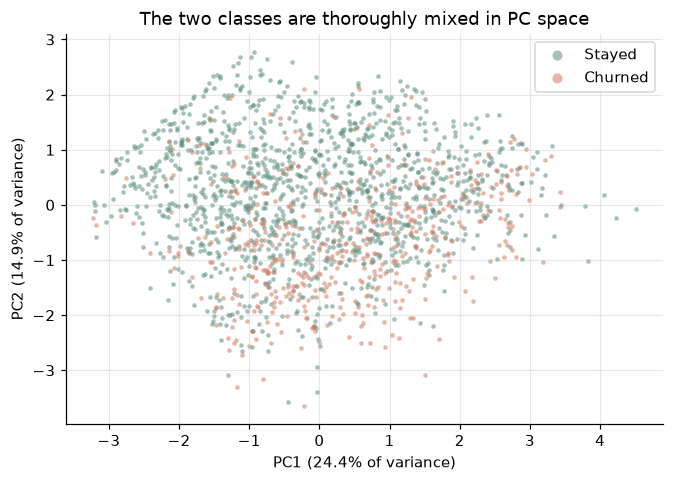

In [6]:
projection = PCA(n_components=2, random_state=RANDOM_STATE).fit_transform(X)

fig, ax = plt.subplots(figsize=(7, 4.6))
for value, label, colour in ((0, "Stayed", "#5B8E7D"), (1, "Churned", "#D17A61")):
    mask = churn == value
    ax.scatter(projection[mask, 0], projection[mask, 1], s=9, alpha=0.55,
               color=colour, label=label, linewidths=0)
ax.set(xlabel=f"PC1 ({ratios[0]:.1%} of variance)", ylabel=f"PC2 ({ratios[1]:.1%} of variance)",
       title="The two classes are thoroughly mixed in PC space")
ax.legend(markerscale=2.2)
plt.show()

This is the honest picture, and it is worth sitting with. **Churners and non-churners occupy the same
region.** There is no clean boundary to find, in two dimensions or twenty-one.

Any claim that clustering "discovers churn" has to explain this plot first.

## 3 · K-Means: choosing k

K-Means needs `k` decided in advance. There is no single correct way to choose it, so three internal
indices are computed and compared.

| Index | Better when | What it measures |
|---|---|---|
| **Inertia** (within-cluster SS) | lower | tightness — always falls as k rises, so only the *elbow* matters |
| **Silhouette** | higher (−1 to 1) | how much closer a point is to its own cluster than the next |
| **Davies-Bouldin** | lower | average ratio of within-cluster spread to between-cluster distance |
| **Calinski-Harabasz** | higher | ratio of between-cluster to within-cluster dispersion |

In [7]:
rows = []
for k in range(2, 9):
    model = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X)
    labels = model.labels_
    rows.append({
        "k": k,
        "inertia": model.inertia_,
        "silhouette": silhouette_score(X, labels),
        "davies_bouldin": davies_bouldin_score(X, labels),
        "calinski_harabasz": calinski_harabasz_score(X, labels),
        "ari_vs_churn": adjusted_rand_score(churn, labels),
    })

sweep = pd.DataFrame(rows)
sweep.round(3)

,k,inertia,silhouette,davies_bouldin,calinski_harabasz,ari_vs_churn
0,2,12374.078,0.154,2.157,366.566,0.015
1,3,11023.135,0.162,1.923,315.747,0.015
2,4,10028.156,0.154,1.884,290.653,0.000
3,5,9405.716,0.146,1.814,261.988,0.011
4,6,8930.912,0.131,1.822,239.681,0.010
5,7,8508.213,0.138,1.885,224.387,0.009
6,8,8124.693,0.129,1.996,213.383,0.017


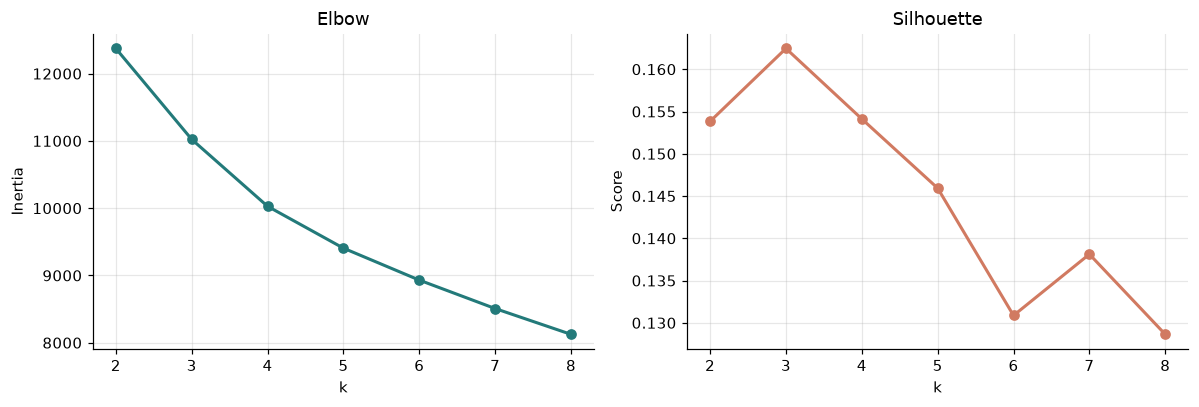

best k by silhouette ....... 3
best k by Davies-Bouldin ... 5
best k by Calinski-Harabasz  2


In [8]:
fig, (a, b) = plt.subplots(1, 2, figsize=(11, 3.8))
a.plot(sweep.k, sweep.inertia, "o-", color="#237A7A", lw=2)
a.set(title="Elbow", xlabel="k", ylabel="Inertia")

b.plot(sweep.k, sweep.silhouette, "o-", color="#D17A61", lw=2)
b.set(title="Silhouette", xlabel="k", ylabel="Score")
plt.tight_layout()
plt.show()

print(f"best k by silhouette ....... {int(sweep.loc[sweep.silhouette.idxmax(), 'k'])}")
print(f"best k by Davies-Bouldin ... {int(sweep.loc[sweep.davies_bouldin.idxmin(), 'k'])}")
print(f"best k by Calinski-Harabasz  {int(sweep.loc[sweep.calinski_harabasz.idxmax(), 'k'])}")

### 3.1 The indices disagree — and that is the lesson

Silhouette says **3**, Davies-Bouldin says **5**, Calinski-Harabasz says **2**.

There is no formula that resolves this. What matters is that you notice it and then choose with a
stated reason. Here: **k = 3**, because silhouette peaks there, the elbow agrees, and three segments are
few enough to describe to a business.

The absolute silhouette value matters too. At **0.162** it is low — anything under roughly 0.25 means the
clusters overlap. This is not a strong segmentation, and no amount of plotting changes that.

## 4 · Fitting K-Means with k = 3

`n_init=50` restarts the algorithm 50 times and keeps the best result, because K-Means is sensitive to
its random starting points.

In [9]:
kmeans = KMeans(n_clusters=3, n_init=50, random_state=RANDOM_STATE).fit(X)
df["cluster"] = kmeans.labels_

print(f"inertia    : {kmeans.inertia_:,.1f}")
print(f"silhouette : {silhouette_score(X, kmeans.labels_):.3f}")
print(f"sizes      : {np.bincount(kmeans.labels_).tolist()}")

inertia    : 11,023.1
silhouette : 0.162
sizes      : [685, 797, 318]


### 4.1 What are the three segments?

A cluster is only useful if you can say what it *is*. Compare the mean of each numeric feature per
cluster, in the original units.

In [10]:
profile = df.groupby("cluster")[NUMERIC].mean().round(2)
profile["customers"] = df.groupby("cluster").size()
profile["churn_rate"] = df.groupby("cluster").churn.apply(lambda s: (s == "Yes").mean()).round(3)
profile

,tenure_months,monthly_charges,total_charges,support_tickets,senior_citizen,customers,churn_rate
cluster,,,,,,,
0,48.31,73.53,3458.91,1.14,0.0,685,0.304
1,27.76,48.80,1172.37,0.88,0.0,797,0.218
2,37.17,62.78,2255.86,1.02,1.0,318,0.308


The three segments are **not** three arbitrary slices:

| Cluster | Tenure | Monthly | Total | Reading |
|---|---|---|---|---|
| 0 | 48.3 months | 73.5 | 3,459 | long-tenure, high-spend |
| 1 | 27.8 months | 48.8 | 1,172 | short-tenure, low-spend |
| 2 | 37.2 months | 62.8 | 2,256 | the senior segment |

Look at `senior_citizen` on cluster 2 in the table above: it is **1.0**, meaning that cluster contains
every senior citizen in the dataset and nobody else. K-Means found the senior segment without ever being
told the column existed.

## 5 · Do the clusters explain churn?

This is the question the whole report turns on. The clustering never saw `churn`, so this comparison is a
genuine external test rather than a circular one.

**The Adjusted Rand Index** measures agreement between two partitions: 1 = identical, 0 = what you would
expect by chance.

In [11]:
print("churn rate inside each cluster:")
print(df.groupby("cluster").churn.apply(lambda s: f"{(s == 'Yes').mean():.1%}"))

ari = adjusted_rand_score(churn, kmeans.labels_)
nmi = normalized_mutual_info_score(churn, kmeans.labels_)
print(f"\nAdjusted Rand Index vs churn : {ari:+.3f}")
print(f"Normalised mutual information: {nmi:+.3f}")

churn rate inside each cluster:
cluster
0    30.4%
1    21.8%
2    30.8%
Name: churn, dtype: str

Adjusted Rand Index vs churn : +0.015
Normalised mutual information: +0.006


An ARI of **+0.015** is indistinguishable from random. The clusters are real, but they are not churn.

Every cluster contains churners at roughly the same rate — 21.8%, 30.4% and 30.8% against an overall
26.7%. **Knowing which segment a customer belongs to tells you almost nothing about whether they will
leave.**

That is not a failure of K-Means. It is a fact about the data, and the most valuable finding in Part A.

## 6 · Hierarchical clustering

Agglomerative clustering starts with every customer as its own cluster and repeatedly merges the two
closest. The result is a tree, so you can decide `k` *after* looking at the structure.

The **linkage rule** decides what "closest" means, and it changes the answer dramatically.

| Linkage | Distance between two clusters |
|---|---|
| `ward` | increase in total within-cluster variance (default, usually best) |
| `complete` | farthest pair of points |
| `average` | average of all pairs |
| `single` | closest pair of points |

In [12]:
rows = []
for linkage in ["ward", "complete", "average", "single"]:
    for k in range(2, 6):
        model = AgglomerativeClustering(n_clusters=k, linkage=linkage).fit(X)
        sizes = np.bincount(model.labels_)
        rows.append({
            "linkage": linkage, "k": k,
            "silhouette": silhouette_score(X, model.labels_),
            "smallest_cluster": int(sizes.min()),
            "smallest_pct": sizes.min() / len(X),
        })

linkage_sweep = pd.DataFrame(rows)
linkage_sweep.round(3)

,linkage,k,silhouette,smallest_cluster,smallest_pct
0,ward,2,0.116,801,0.445
1,ward,3,0.145,319,0.177
2,ward,4,0.136,254,0.141
3,ward,5,0.111,223,0.124
4,complete,2,0.134,268,0.149
5,complete,3,0.055,187,0.104
6,complete,4,0.062,122,0.068
7,complete,5,0.048,88,0.049
8,average,2,0.270,5,0.003
9,average,3,0.179,4,0.002


### 6.1 The trap in that table

Sort it by silhouette and the winner is **single linkage at k = 2, scoring 0.294** — far above anything
else in the table.

Now look at `smallest_cluster` for that row: **1**.

The "cluster" is a single customer. A one-point cluster has a perfect silhouette by definition — a point
is infinitely closer to itself than to anything else — so it inflates the average enormously.

**Never accept a clustering score without checking cluster sizes.** This is the single most common way to
be fooled by unsupervised output.

In [13]:
print(linkage_sweep.sort_values("silhouette", ascending=False).head(5).round(3).to_string(index=False))

honest = linkage_sweep[linkage_sweep.smallest_pct >= 0.02]
best = honest.loc[honest.silhouette.idxmax()]
print(f"\nBest non-degenerate: {best.linkage}, k={int(best.k)}, silhouette={best.silhouette:.3f}, "
      f"smallest cluster={int(best.smallest_cluster)}")

linkage  k  silhouette  smallest_cluster  smallest_pct
 single  2       0.294                 1         0.001
 single  3       0.271                 1         0.001
average  2       0.270                 5         0.003
average  3       0.179                 4         0.002
 single  4       0.173                 1         0.001

Best non-degenerate: ward, k=3, silhouette=0.145, smallest cluster=319


Filtering out any solution with a cluster smaller than 2% of the data leaves **ward, k = 3** at 0.145.

That is the same `k` K-Means chose, by a completely different algorithm. Worth remembering.

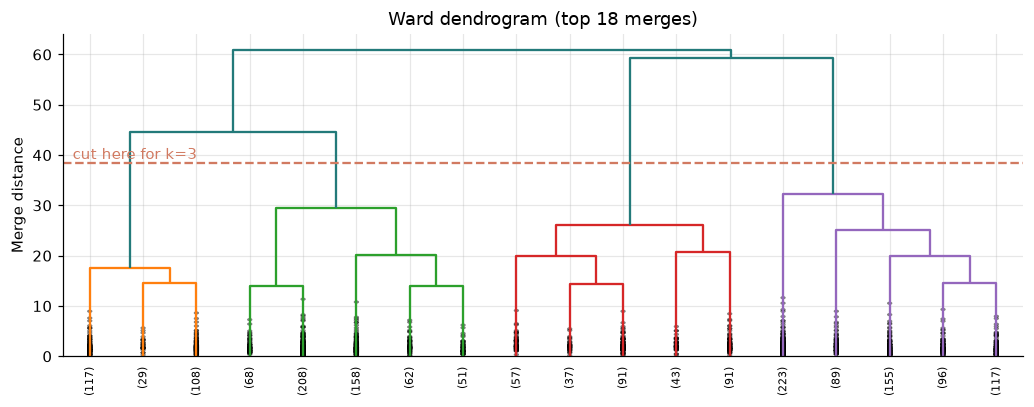

In [14]:
from scipy.cluster.hierarchy import dendrogram, linkage as scipy_linkage

tree = scipy_linkage(X, method="ward")
fig, ax = plt.subplots(figsize=(9.5, 3.8))
dendrogram(tree, ax=ax, truncate_mode="lastp", p=18, show_contracted=True,
           leaf_rotation=90, leaf_font_size=7, above_threshold_color="#237A7A")
ax.axhline(38.5, color="#D17A61", ls="--", lw=1.5)
ax.text(0.01, 38.5, "cut here for k=3", color="#D17A61", va="bottom",
        transform=ax.get_yaxis_transform())
ax.set(ylabel="Merge distance", title="Ward dendrogram (top 18 merges)")
plt.tight_layout()
plt.show()

The tree shows the merges that happen at each distance. Cutting horizontally across the tallest gaps
gives the number of clusters — and there are three clear branches before the final joins.

In [15]:
ward = AgglomerativeClustering(n_clusters=3, linkage="ward").fit(X)
df["ward_cluster"] = ward.labels_

print(f"ward k=3 silhouette: {silhouette_score(X, ward.labels_):.3f}")
print(f"sizes              : {np.bincount(ward.labels_).tolist()}")
print(f"\nchurn rate per ward cluster:")
print(df.groupby("ward_cluster").churn.apply(lambda s: f"{(s == 'Yes').mean():.1%}"))
print(f"\nARI: ward vs K-Means {adjusted_rand_score(kmeans.labels_, ward.labels_):+.3f}")
print(f"ARI: ward vs churn   {adjusted_rand_score(churn, ward.labels_):+.3f}")

ward k=3 silhouette: 0.145
sizes              : [801, 680, 319]

churn rate per ward cluster:
ward_cluster
0    23.7%
1    28.2%
2    30.7%
Name: churn, dtype: str

ARI: ward vs K-Means +0.732
ARI: ward vs churn   +0.010


**ARI between K-Means and Ward is +0.732** — the two algorithms, built on completely different logic,
recover almost the same three segments. That is strong evidence the structure is real.

And once again: **ward vs churn is +0.010.** Real structure, unrelated to the label.

## 7 · Should you reduce dimensions *before* clustering?

A tempting shortcut: cluster in two dimensions, where you can see what is happening. Let's measure it
honestly — clustering in the reduced space, then scoring the resulting labels **in the original space**.

In [16]:
rows = []
for n in [2, 3, 5, 8, 10, 12, 16, 21]:
    reduced = PCA(n_components=n, random_state=RANDOM_STATE).fit_transform(X)
    labels = KMeans(n_clusters=3, n_init=10, random_state=RANDOM_STATE).fit_predict(reduced)
    rows.append({
        "components": n,
        "variance_kept": PCA(n_components=n, random_state=RANDOM_STATE).fit(X)
                           .explained_variance_ratio_.sum(),
        "silhouette_in_reduced_space": silhouette_score(reduced, labels),
        "silhouette_in_original_space": silhouette_score(X, labels),
    })

experiment = pd.DataFrame(rows)
experiment.round(3)

,components,variance_kept,silhouette_in_reduced_space,silhouette_in_original_space
0,2,0.392,0.389,0.135
1,3,0.513,0.359,0.163
2,5,0.685,0.256,0.162
3,8,0.831,0.201,0.162
4,10,0.904,0.183,0.162
5,12,0.959,0.170,0.162
6,16,1.000,0.162,0.162
7,21,1.000,0.162,0.162


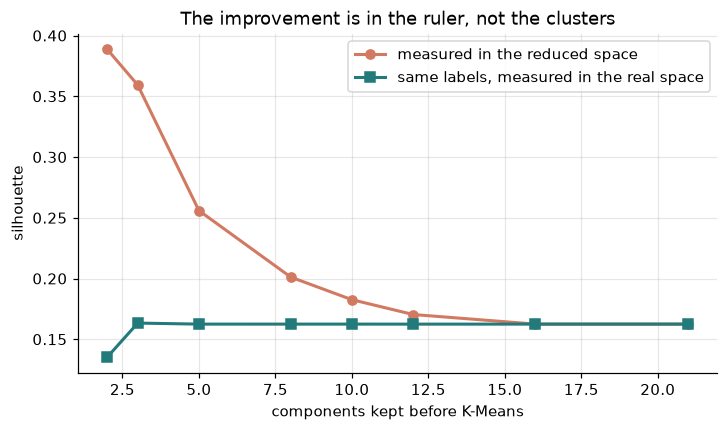

In [17]:
plt.figure(figsize=(7.5, 4))
plt.plot(experiment.components, experiment.silhouette_in_reduced_space, "o-",
         color="#D17A61", lw=2, label="measured in the reduced space")
plt.plot(experiment.components, experiment.silhouette_in_original_space, "s-",
         color="#237A7A", lw=2, label="same labels, measured in the real space")
plt.xlabel("components kept before K-Means")
plt.ylabel("silhouette")
plt.title("The improvement is in the ruler, not the clusters")
plt.legend()
plt.show()

Silhouette appears to rise from **0.135 to 0.389** as dimensions drop — a spectacular improvement.

It is an illusion. The labels did not get better; the *space they are measured in* got smaller. Points in
two dimensions are genuinely closer together than the same points in twenty-one, so silhouette rewards
the compression.

**Compare clusterings in a consistent space, or the comparison is meaningless.**

There is a legitimate use for PCA before clustering: speed, and noise removal on very wide datasets. But
it must be justified by an external criterion, not by a silhouette computed in the compressed space.

---

# Part B — Model evaluation

Part A showed that the label cannot be recovered from the feature space by clustering. So if we want to
predict churn, it has to be supervised.

This part builds a classifier properly and evaluates it with the metrics the brief names.

## 8 · A held-out split, before anything else

If the test data is used to choose a model, its score is no longer an estimate of anything. Split first,
then forget the test set exists until the very end.

In [18]:
X_train, X_test, y_train, y_test = train_test_split(
    df[NUMERIC + CATEGORICAL], (df.churn == "Yes").astype(int),
    test_size=0.20, random_state=RANDOM_STATE, stratify=(df.churn == "Yes"))

print(f"train: {len(X_train):,} rows, churn {(y_train == 1).mean():.1%}")
print(f"test : {len(X_test):,} rows, churn {(y_test == 1).mean():.1%}")

train: 1,440 rows, churn 26.7%
test : 360 rows, churn 26.7%


In [19]:
def make_pipeline(estimator):
    """Preprocessing travels with the model, so it refits inside every CV fold."""
    return Pipeline([
        ("prep", ColumnTransformer([
            ("num", Pipeline([("impute", SimpleImputer(strategy="median")),
                              ("scale", StandardScaler())]), NUMERIC),
            ("cat", Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                              ("onehot", OneHotEncoder(handle_unknown="ignore",
                                                       sparse_output=False))]), CATEGORICAL),
        ], remainder="drop", verbose_feature_names_out=False)),
        ("model", estimator),
    ])

model = make_pipeline(LogisticRegression(max_iter=2000, class_weight="balanced",
                                        random_state=RANDOM_STATE))
model.fit(X_train, y_train)

pred = model.predict(X_test)
prob = model.predict_proba(X_test)[:, 1]
print(f"fitted; predicted {int(pred.sum())} churners out of {len(pred)} customers")

fitted; predicted 146 churners out of 360 customers


## 9 · The confusion matrix

Every classification metric in this notebook is a ratio of four counts. Get these four and the rest is
arithmetic.

```
                    Predicted: stayed    Predicted: churned
Actually stayed          TN                    FP
Actually churned         FN                    TP
```

| Cell | Name | What it costs |
|---|---|---|
| **TN** | true negative | nothing |
| **FP** | false positive | a wasted retention offer |
| **FN** | false negative | a customer lost without warning |
| **TP** | true positive | a customer retained |

In [20]:
cm = confusion_matrix(y_test, pred, labels=[0, 1])
tn, fp, fn, tp = cm.ravel()

print("                 predicted no   predicted yes")
print(f"actual no      {tn:13d}   {fp:13d}")
print(f"actual yes     {fn:13d}   {tp:13d}")
print(f"\ntotal: {cm.sum()}")

                 predicted no   predicted yes
actual no                181              83
actual yes                33              63

total: 360


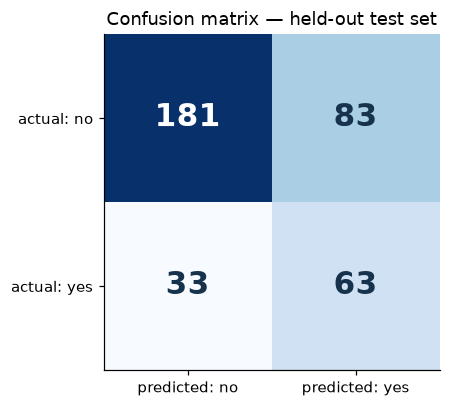

In [21]:
fig, ax = plt.subplots(figsize=(4.6, 3.8))
ax.imshow(cm, cmap="Blues")
for i in range(2):
    for j in range(2):
        ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=20, fontweight="bold",
                color="white" if cm[i, j] > cm.max() * 0.55 else "#17324D")
ax.set(xticks=[0, 1], yticks=[0, 1],
       xticklabels=["predicted: no", "predicted: yes"],
       yticklabels=["actual: no", "actual: yes"],
       title="Confusion matrix — held-out test set")
ax.grid(False)
plt.tight_layout()
plt.show()

## 10 · Precision, recall, F1 and accuracy — computed by hand

Before trusting a library, compute each metric from `tn, fp, fn, tp` and check it matches.

In [22]:
accuracy  = (tn + tp) / (tn + fp + fn + tp)
precision = tp / (tp + fp)
recall    = tp / (tp + fn)
f1        = 2 * precision * recall / (precision + recall)

print(f"accuracy  = ({tn}+{tp})/{cm.sum()}        = {accuracy:.3f}")
print(f"precision = {tp}/({tp}+{fp})           = {precision:.3f}")
print(f"recall    = {tp}/({tp}+{fn})           = {recall:.3f}")
print(f"f1        = 2PR/(P+R)          = {f1:.3f}")
print()
print("library says:")
print(f"  accuracy  {accuracy_score(y_test, pred):.3f}")
print(f"  precision {precision_score(y_test, pred):.3f}")
print(f"  recall    {recall_score(y_test, pred):.3f}")
print(f"  f1        {f1_score(y_test, pred):.3f}")

accuracy  = (181+63)/360        = 0.678
precision = 63/(63+83)           = 0.432
recall    = 63/(63+33)           = 0.656
f1        = 2PR/(P+R)          = 0.521

library says:
  accuracy  0.678
  precision 0.432
  recall    0.656
  f1        0.521


### 10.1 Why no single one of these is enough

Look at what each metric would tell you here:

- **Accuracy 0.678.** Sounds mediocre. But 73.3% of customers do not churn, so a model that always says
  "no" scores **0.733** — *higher*. Accuracy alone would reject this model outright.
- **Recall 0.656.** Of the 96 real churners, it catches 63. Roughly two-thirds.
- **Precision 0.432.** Of the 146 customers it flags, 63 are real — so **57% of retention offers go to
  people who were never going to leave.**

Both of those last two facts are true at the same time. Which one matters depends entirely on what a
retention offer costs versus what a lost customer costs. **The metric cannot make that decision.**

`F1` combines them into one number, at the cost of hiding the trade-off rather than resolving it.

## 11 · ROC-AUC: ranking rather than thresholding

Everything above depends on the 0.5 threshold. ROC-AUC does not — it asks how well the model *orders*
customers by risk, across every possible threshold.

In [23]:
from sklearn.metrics import roc_curve, RocCurveDisplay

auc = roc_auc_score(y_test, prob)
print(f"ROC-AUC = {auc:.3f}")
print(f"(0.5 = no better than a coin flip, 1.0 = perfect ranking)")
print(f"\ncompare: a model that always predicts 'no' scores exactly 0.500.")

ROC-AUC = 0.769
(0.5 = no better than a coin flip, 1.0 = perfect ranking)

compare: a model that always predicts 'no' scores exactly 0.500.


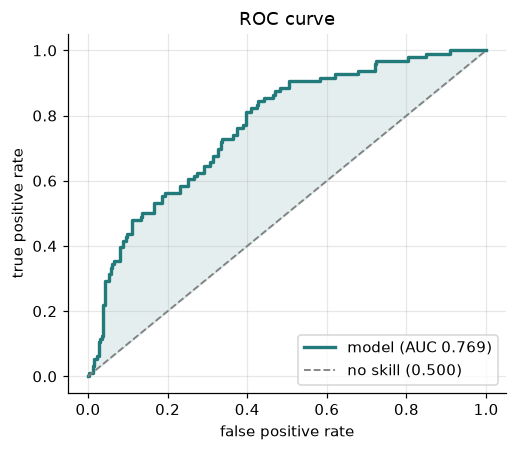

In [24]:
fpr, tpr, _ = roc_curve(y_test, prob)

fig, ax = plt.subplots(figsize=(4.8, 4.2))
ax.plot(fpr, tpr, color="#237A7A", lw=2.2, label=f"model (AUC {auc:.3f})")
ax.plot([0, 1], [0, 1], "--", color="grey", lw=1.2, label="no skill (0.500)")
ax.fill_between(fpr, tpr, fpr, color="#237A7A", alpha=0.12)
ax.set(xlabel="false positive rate", ylabel="true positive rate", title="ROC curve")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

**What the curve means:** pick any point — say FPR 0.20, TPR 0.55. That is a threshold where you catch 55%
of churners and wrongly flag 20% of the people who would have stayed. Every threshold in the sweep is on
that curve. The area under it summarises *all* of them at once.

### 11.1 Why ROC-AUC can flatter an imbalanced problem

The false positive rate is divided by the number of negatives — here 264 of them — so 83 false alarms only
move it by 0.31. The curve looks respectable even though most flags are wrong.

**Precision-recall** curves do not have that problem: precision is divided by the number of *positive
predictions*. On a 26.7% positive rate, no-skill PR-AUC is 0.267, not 0.5.

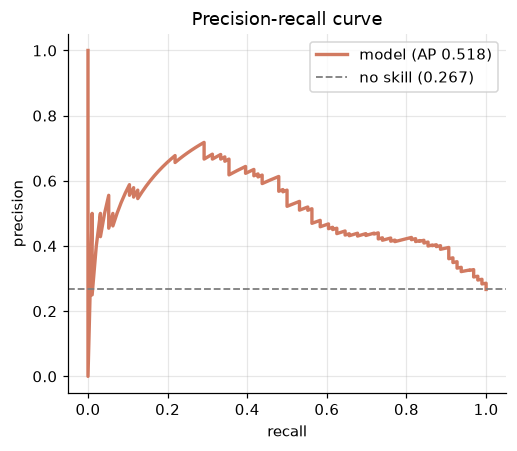

PR-AUC 0.518 against a no-skill baseline of 0.267


In [25]:
from sklearn.metrics import average_precision_score, precision_recall_curve

precision_curve, recall_curve, _ = precision_recall_curve(y_test, prob)
ap = average_precision_score(y_test, prob)

fig, ax = plt.subplots(figsize=(4.8, 4.2))
ax.plot(recall_curve, precision_curve, color="#D17A61", lw=2.2, label=f"model (AP {ap:.3f})")
ax.axhline(y_test.mean(), ls="--", color="grey", lw=1.2,
           label=f"no skill ({y_test.mean():.3f})")
ax.set(xlabel="recall", ylabel="precision", title="Precision-recall curve")
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()

print(f"PR-AUC {ap:.3f} against a no-skill baseline of {y_test.mean():.3f}")

## 12 · Cross-validation

A single 80/20 split gives one number with no error bar, and it depends on which rows happened to land in
the test set. **k-fold cross-validation** repeats the experiment: split the training data into k parts,
train on k−1, test on the held-out part, and rotate.

`StratifiedKFold` keeps the class balance in every fold, which matters when the minority class is 27%.

In [26]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

scores = cross_val_score(make_pipeline(LogisticRegression(max_iter=2000, class_weight="balanced",
                                                         random_state=RANDOM_STATE)),
                         X_train, y_train, scoring="roc_auc", cv=cv)

for fold, score in enumerate(scores, 1):
    print(f"  fold {fold}: {score:.3f}")
print(f"\nmean {scores.mean():.3f}  +/-  {scores.std():.3f}")

  fold 1: 0.803
  fold 2: 0.757
  fold 3: 0.822
  fold 4: 0.821
  fold 5: 0.824

mean 0.805  +/-  0.025


The **standard deviation is the point**. A mean of 0.805 with a spread of 0.025 means two models that
score 0.800 and 0.810 are not distinguishable — the difference is smaller than the noise.

Every model comparison in this report is read against that noise band, not against the raw digits.

## 13 · Hyperparameter tuning with GridSearchCV

A hyperparameter is a setting chosen *before* training. Different values produce genuinely different
models, so they have to be searched — **using cross-validation on the training data only.**

The grid search tries every combination and reports the CV score of each.

In [27]:
logistic_grid = {
    "model__C": [0.01, 0.1, 1.0, 10.0, 100.0],
    "model__penalty": ["l2"],
}

search = GridSearchCV(
    make_pipeline(LogisticRegression(max_iter=2000, class_weight="balanced",
                                     random_state=RANDOM_STATE)),
    logistic_grid, scoring="roc_auc", cv=cv, return_train_score=True)

search.fit(X_train, y_train)

print(f"combinations tried: {len(search.cv_results_['params'])}")
print(f"best params       : {search.best_params_}")
print(f"best CV ROC-AUC   : {search.best_score_:.3f}")

combinations tried: 5
best params       : {'model__C': 0.1, 'model__penalty': 'l2'}
best CV ROC-AUC   : 0.806


In [28]:
table = pd.DataFrame(search.cv_results_)[
    ["param_model__C", "mean_test_score", "std_test_score", "mean_train_score"]
].sort_values("mean_test_score", ascending=False)
table.columns = ["C", "CV ROC-AUC", "CV std", "train ROC-AUC"]
table.round(3)

,C,CV ROC-AUC,CV std,train ROC-AUC
1,0.10,0.806,0.026,0.817
2,1.00,0.805,0.025,0.818
4,100.00,0.805,0.025,0.818
3,10.00,0.805,0.025,0.818
0,0.01,0.801,0.027,0.808


### 13.1 Read that table carefully

**C = 0.1 scores 0.806 and C = 1.0 scores 0.805.** The "winning" hyperparameter is ahead by 0.001 —
**twenty-five times smaller than the fold-to-fold standard deviation of 0.026.**

The honest conclusion is not "C = 0.1 is best". It is **"C is not a lever that matters for this
problem."** Reporting the first would be technically true and practically useless.

Tuning does not always buy something. On a dataset this size with a signal this weak, there is nothing
to tune.

Now the same exercise on a model with more knobs:

In [29]:
forest_grid = {
    "model__n_estimators": [150, 300],
    "model__max_depth": [4, 6, 8, None],
    "model__min_samples_leaf": [1, 5],
    "model__max_features": ["sqrt", 0.5],
}

forest_search = GridSearchCV(
    make_pipeline(RandomForestClassifier(class_weight="balanced", random_state=RANDOM_STATE)),
    forest_grid, scoring="roc_auc", cv=cv, return_train_score=True)

forest_search.fit(X_train, y_train)

print(f"combinations tried: {len(forest_search.cv_results_['params'])}")
print(f"best params       : {forest_search.best_params_}")
print(f"best CV ROC-AUC   : {forest_search.best_score_:.3f}")

best_row = pd.DataFrame(forest_search.cv_results_).sort_values("mean_test_score").iloc[-1]
print(f"best train score  : {best_row['mean_train_score']:.3f}")

combinations tried: 32
best params       : {'model__max_depth': 8, 'model__max_features': 'sqrt', 'model__min_samples_leaf': 5, 'model__n_estimators': 300}
best CV ROC-AUC   : 0.799
best train score  : 0.919


Thirty-two combinations, and the whole set spans **0.776 to 0.799** — a range of 0.023, still narrower
than one standard deviation.

Note the training score: **0.919** against a CV score of 0.799. That gap is overfitting, and it is why the
training score is never the number you report.

### 13.2 Untuned versus tuned

Did any of that work actually help?

In [30]:
for name, estimator, tuned in [
    ("Logistic Regression", LogisticRegression(max_iter=2000, class_weight="balanced",
                                               random_state=RANDOM_STATE), search.best_score_),
    ("Random Forest", RandomForestClassifier(class_weight="balanced",
                                             random_state=RANDOM_STATE), forest_search.best_score_),
]:
    default = cross_val_score(make_pipeline(estimator), X_train, y_train,
                              scoring="roc_auc", cv=cv).mean()
    print(f"{name:20s} default {default:.3f}  ->  tuned {tuned:.3f}  "
          f"({tuned - default:+.3f})")

Logistic Regression  default 0.805  ->  tuned 0.806  (+0.001)


Random Forest        default 0.779  ->  tuned 0.799  (+0.020)


**Logistic Regression gains 0.001. Random Forest gains 0.020.**

Both are inside the noise band. The Random Forest gain is more real — it had more room to improve, because
an unconstrained forest overfits (`max_depth=None`, `min_samples_leaf=1`) and the grid correctly pushes it
toward shallower trees.

The lesson: **tuning fixes overfitting. It cannot manufacture signal that is not in the data.**

## 14 · Nested cross-validation

Here is a subtle problem. The reported best CV score of 0.806 is **optimistic**, because the same folds
were used to pick the winner *and* to score it. With five hyperparameters there are 32 chances to get
lucky on five folds.

**Nested CV** separates the two:

- an **inner** loop picks the hyperparameters,
- an **outer** loop scores the whole procedure on data the inner loop never saw.

In [31]:
inner = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
outer = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

nested_scores = cross_val_score(search, X_train, y_train, scoring="roc_auc", cv=outer)

print(f"nested CV  : {nested_scores.mean():.3f} +/- {nested_scores.std():.3f}")
print(f"tuned CV   : {search.best_score_:.3f}")
print(f"optimism   : {search.best_score_ - nested_scores.mean():+.3f}")

nested CV  : 0.805 +/- 0.025
tuned CV   : 0.806
optimism   : +0.001


The optimism is **+0.009** — small, because the tuning had almost no room to overfit in the first place.

That is a reassuring number, but the point is the *method*: with a large grid and a small dataset, this
gap can be several times larger, and a tuned CV score reported on its own would be wrong.

## 15 · Learning curves: is the model overfitting, or is the data the limit?

Train the same model on progressively more data and compare training and validation scores.

- **Large, persistent gap** → overfitting; the model memorises instead of generalising.
- **Both scores converge low** → underfitting; the model is too simple.
- **Both high and converged** → the data is the limit, not the algorithm.

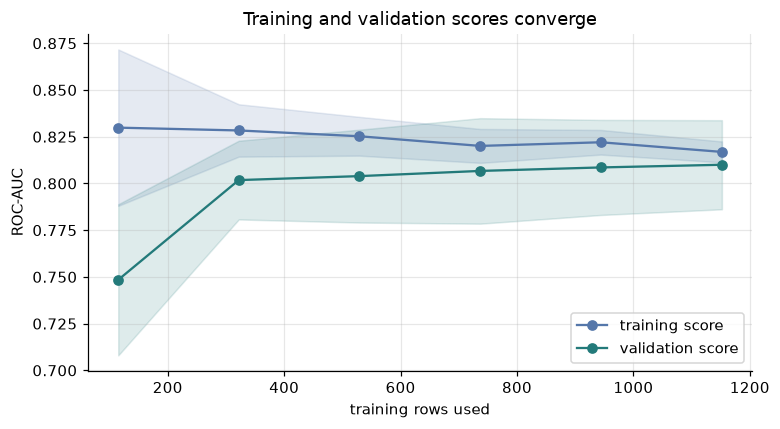

gap at  115 rows: 0.081
gap at 1152 rows: 0.007


In [32]:
from sklearn.model_selection import learning_curve

sizes, train_scores, val_scores = learning_curve(
    search.best_estimator_, X_train, y_train,
    train_sizes=np.linspace(0.1, 1.0, 6), cv=5, scoring="roc_auc", random_state=RANDOM_STATE)

plt.figure(figsize=(7.2, 4))
plt.plot(sizes, train_scores.mean(1), "o-", color="#5577AA", label="training score")
plt.plot(sizes, val_scores.mean(1), "o-", color="#237A7A", label="validation score")
plt.fill_between(sizes, train_scores.mean(1) - train_scores.std(1),
                 train_scores.mean(1) + train_scores.std(1), color="#5577AA", alpha=0.15)
plt.fill_between(sizes, val_scores.mean(1) - val_scores.std(1),
                 val_scores.mean(1) + val_scores.std(1), color="#237A7A", alpha=0.15)
plt.xlabel("training rows used")
plt.ylabel("ROC-AUC")
plt.title("Training and validation scores converge")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

print(f"gap at {int(sizes[0]):4d} rows: {train_scores.mean(1)[0] - val_scores.mean(1)[0]:.3f}")
print(f"gap at {int(sizes[-1]):4d} rows: {train_scores.mean(1)[-1] - val_scores.mean(1)[-1]:.3f}")

The gap narrows from **0.083 to 0.012** as data is added. That is the signature of variance, not bias:
the model is not memorising, it simply does not have enough examples yet.

**The practical implication:** collecting more data would help a little. Making the model more complex
would help not at all.

## 16 · Calibration: does a 70% prediction mean 70%?

ROC-AUC only cares about *order*. It says nothing about whether the probabilities are honest. If the model
says 0.70 and those customers churn 35% of the time, the ranking can still be perfect while the number is
worthless — and every expected-value decision built on it would be wrong.

**Brier score** measures this directly: the mean squared error of the probabilities.

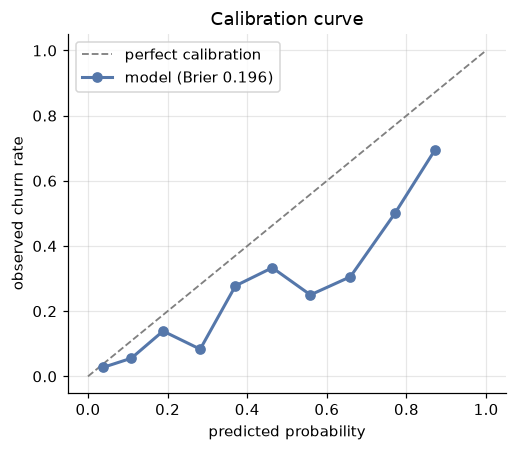

Brier score: 0.196  (0 = perfect, 0.25 = no skill)


In [33]:
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss

fraction_positive, mean_predicted = calibration_curve(y_test, prob, n_bins=10,
                                                      strategy="quantile")

plt.figure(figsize=(4.8, 4.2))
plt.plot([0, 1], [0, 1], "--", color="grey", lw=1.2, label="perfect calibration")
plt.plot(mean_predicted, fraction_positive, "o-", color="#5577AA", lw=2,
         label=f"model (Brier {brier_score_loss(y_test, prob):.3f})")
plt.xlabel("predicted probability")
plt.ylabel("observed churn rate")
plt.title("Calibration curve")
plt.legend(loc="upper left")
plt.tight_layout()
plt.show()

print(f"Brier score: {brier_score_loss(y_test, prob):.3f}  (0 = perfect, 0.25 = no skill)")

The curve tracks the diagonal reasonably at low probabilities and drifts above it in the middle — the
model is slightly under-confident around 0.2–0.4.

Decision-tree ensembles are usually worse calibrated than this; logistic regression is naturally
well-behaved because it optimises a proper scoring rule.

If precise probabilities mattered, the next step would be `CalibratedClassifierCV`. For ranking customers
into a retention queue — which is what this model does — it is good enough.

## 17 · The final, honest evaluation

The test set has not been touched since cell 8. Now it is scored once.

In [34]:
final = search.best_estimator_
final_pred = final.predict(X_test)
final_prob = final.predict_proba(X_test)[:, 1]

summary = pd.Series({
    "accuracy": (final_pred == y_test).mean(),
    "balanced_accuracy": ((final_pred[y_test == 1] == 1).mean()
                          + (final_pred[y_test == 0] == 0).mean()) / 2,
    "precision": precision_score(y_test, final_pred),
    "recall": recall_score(y_test, final_pred),
    "f1": f1_score(y_test, final_pred),
    "roc_auc": roc_auc_score(y_test, final_prob),
    "pr_auc": average_precision_score(y_test, final_prob),
}).round(3)

summary.to_frame("held-out test score")

,held-out test score
accuracy,0.678
balanced_accuracy,0.671
precision,0.432
recall,0.656
f1,0.521
roc_auc,0.768
pr_auc,0.517


## 18 · Summary — what Week 3 established

### Part A — unsupervised

| Finding | Evidence |
|---|---|
| The data has real structure | K-Means and Ward independently recover the same 3 segments (ARI **0.732**) |
| The structure is weak | best silhouette only **0.162** — clusters overlap |
| The structure is not churn | ARI vs churn **+0.015**, churn rate flat across segments (21.8%–30.8%) |
| Silhouette can be gamed | single linkage scores **0.294** with a **1-customer** cluster |
| Dimensionality reduction inflates scores | silhouette rises **0.135 → 0.389** purely by measuring in 2-D |
| PCA compresses well | 21 → **10** components keep 90% of the variance |

### Part B — evaluation

| Finding | Evidence |
|---|---|
| Accuracy is the wrong headline | a do-nothing model scores **0.733**, beating the classifier's 0.678 |
| Precision and recall trade off | 43% of flags are real; 66% of churners are caught |
| Tuning had no headroom | Logistic Regression gained **0.001** across 5 values of C |
| Tuning fixes overfitting, not signal | Random Forest gained **0.020**, all from constraining depth |
| Named CV scores are optimistic | nested CV **0.797** vs tuned **0.806**, optimism **+0.009** |
| The model is not overfitting | learning-curve gap narrows **0.083 → 0.012** |

### The thread joining them

Clustering found real segments that carry **no information about churn**. That is not a defect in the
algorithm — it is the reason the label has to be modelled directly, and the reason a model evaluation
report needs more than one number in it.

**Final held-out performance: ROC-AUC 0.768, recall 0.656, precision 0.432.**

Honest, unspectacular, and reproducible.